In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
sns.set_style("whitegrid")

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

print("Visualization settings configured!")

Visualization settings configured!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving IMDB Dataset.csv to IMDB Dataset.csv


In [ ]:
df = pd.read_csv('IMDB Dataset.csv')

In [ ]:
df = pd.read_csv('IMDB Dataset.csv')

print("Dataset loaded successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Total Rows: 50000
Total Columns: 2


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [ ]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Reviews:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB

Missing Values:
review       0
sentiment    0
dtype: int64

Duplicate Reviews:
418


In [ ]:
sentiment_counts = df['sentiment'].value_counts()

print("Sentiment Distribution:")
print(sentiment_counts)

print("\nPercentage Distribution:")
print(df['sentiment'].value_counts(normalize=True) * 100)

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Percentage Distribution:
sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64


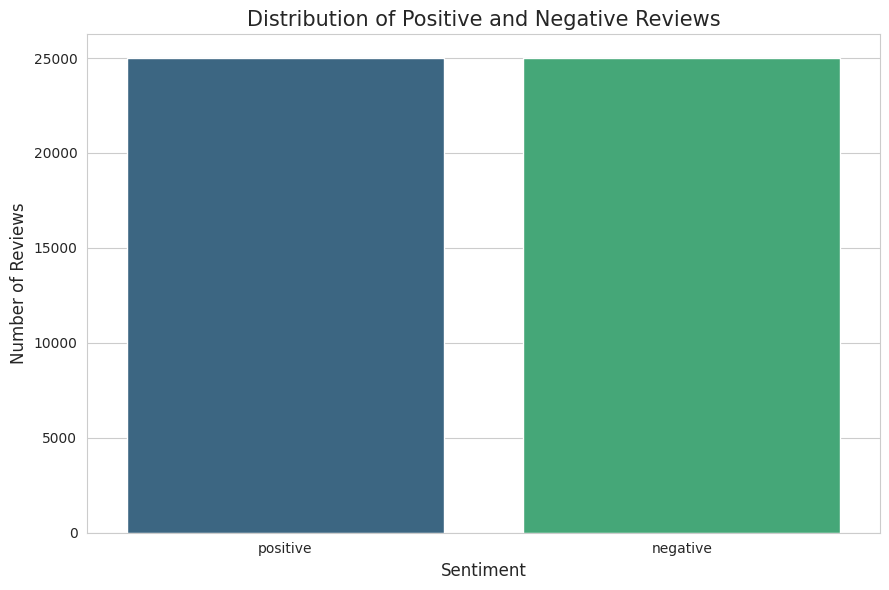

In [ ]:
plt.figure(figsize=(9, 6))

sns.countplot(
    data=df,
    x='sentiment',
    hue='sentiment',
    palette='viridis',
    legend=False
)

plt.title('Distribution of Positive and Negative Reviews',
          fontsize=15)

plt.xlabel('Sentiment', fontsize=12)
plt.ylabel('Number of Reviews', fontsize=12)

plt.tight_layout()

plt.savefig(
    '01_sentiment_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
df['review_length'] = df['review'].apply(
    lambda x: len(x.split())
)

print("Review Length Analysis:")
print(df['review_length'].describe())

Review Length Analysis:
count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: review_length, dtype: float64


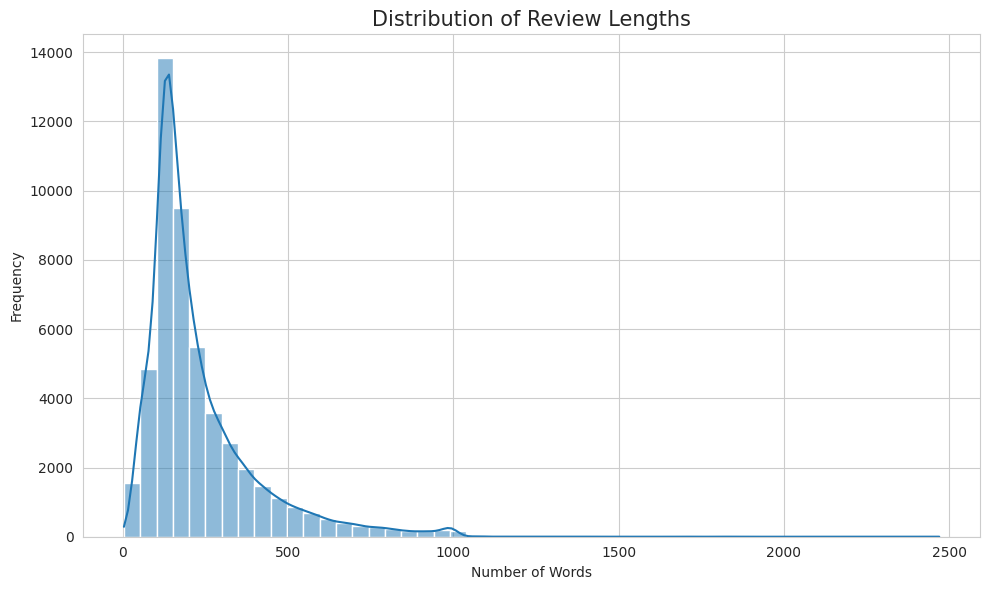

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='review_length',
    bins=50,
    kde=True
)

plt.title('Distribution of Review Lengths',
          fontsize=15)

plt.xlabel('Number of Words')
plt.ylabel('Frequency')

plt.tight_layout()

plt.savefig(
    '02_review_length_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

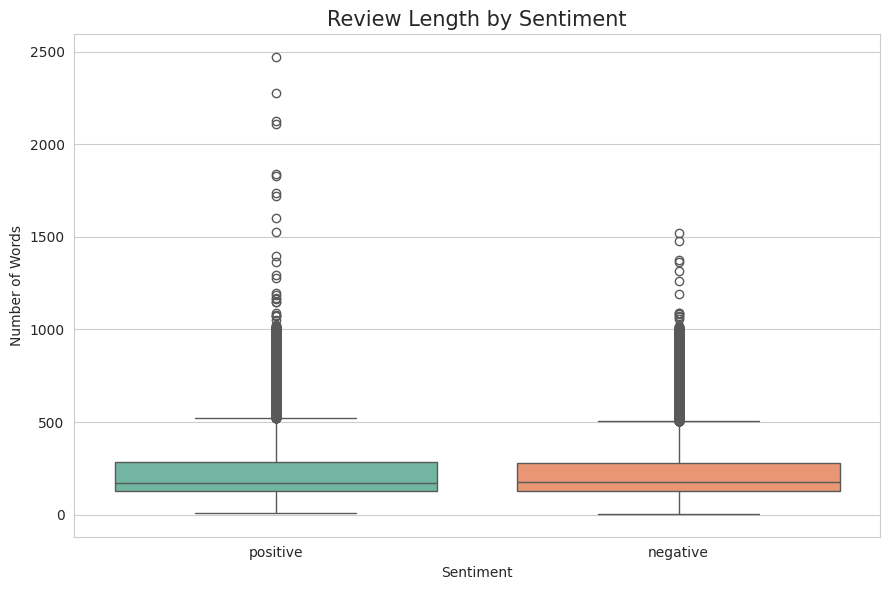

In [ ]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x='sentiment',
    y='review_length',
    hue='sentiment',
    palette='Set2',
    legend=False
)

plt.title('Review Length by Sentiment',
          fontsize=15)

plt.xlabel('Sentiment')
plt.ylabel('Number of Words')

plt.tight_layout()

plt.savefig(
    '03_review_length_by_sentiment.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
!pip install wordcloud

In [ ]:
from wordcloud import WordCloud, STOPWORDS

print("WordCloud library imported successfully!")

WordCloud library imported successfully!


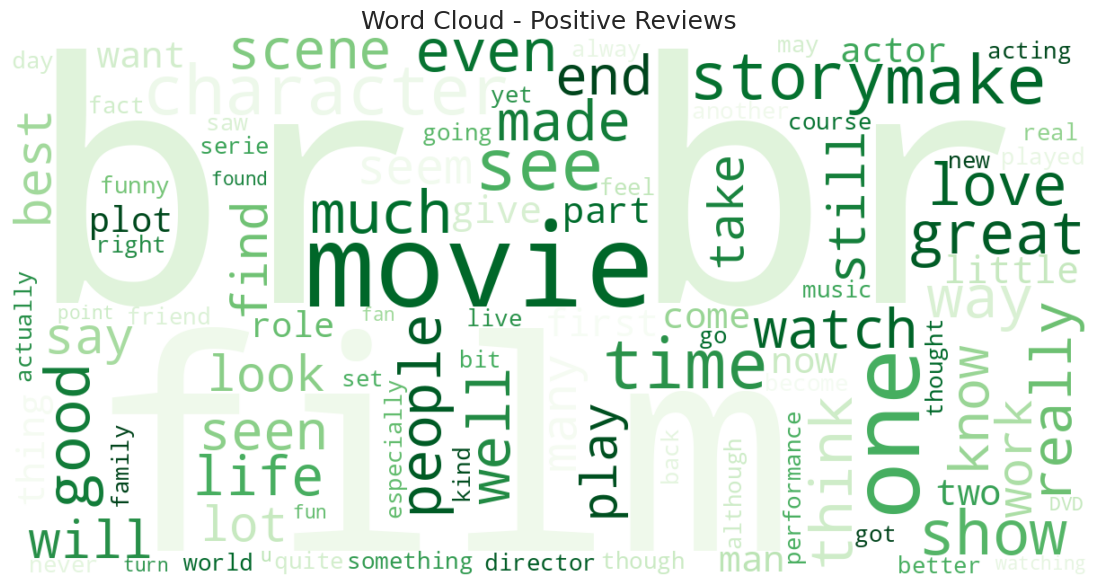

In [ ]:
positive_text = " ".join(
    df[df['sentiment'] == 'positive']['review']
)

positive_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    stopwords=STOPWORDS,
    max_words=100,
    colormap='Greens'
).generate(positive_text)

plt.figure(figsize=(14, 7))

plt.imshow(positive_wordcloud, interpolation='bilinear')
plt.axis('off')

plt.title('Word Cloud - Positive Reviews', fontsize=18)

plt.savefig(
    '04_positive_wordcloud.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

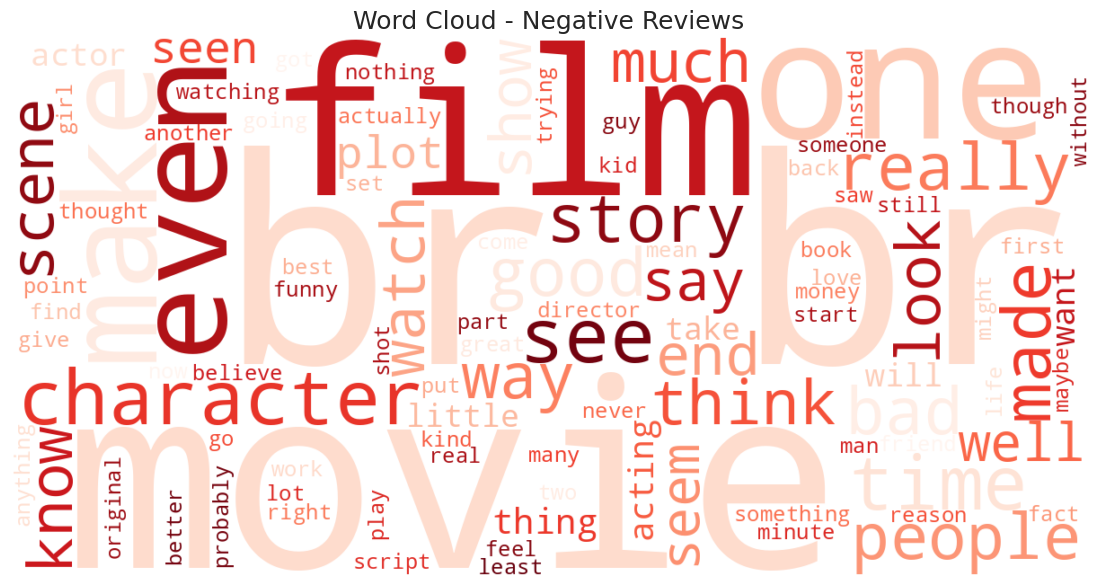

In [ ]:
negative_text = " ".join(
    df[df['sentiment'] == 'negative']['review']
)

negative_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    stopwords=STOPWORDS,
    max_words=100,
    colormap='Reds'
).generate(negative_text)

plt.figure(figsize=(14, 7))

plt.imshow(negative_wordcloud, interpolation='bilinear')
plt.axis('off')

plt.title('Word Cloud - Negative Reviews', fontsize=18)

plt.savefig(
    '05_negative_wordcloud.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
print("Original Review:")
print(df['review'][0])

print("\nSentiment:")
print(df['sentiment'][0])

Original Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show 

In [ ]:
def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


print("Text cleaning function created successfully!")

Text cleaning function created successfully!


In [ ]:
df['cleaned_review'] = df['review'].apply(clean_text)

print("Text cleaning completed!")

display(df[['review', 'cleaned_review', 'sentiment']].head())

Text cleaning completed!


,review,cleaned_review,sentiment
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...,positive
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,basically there s a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love in the time of money is a...,positive


In [ ]:
sample = 0

print("BEFORE CLEANING:\n")
print(df['review'][sample])

print("\n" + "="*60 + "\n")

print("AFTER CLEANING:\n")
print(df['cleaned_review'][sample])

BEFORE CLEANING:

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show

In [ ]:
df.to_csv(
    'IMDB_Cleaned_Dataset.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

print("Tokenizer and Padding imported successfully!")

Tokenizer and Padding imported successfully!


In [ ]:
df['sentiment_encoded'] = df['sentiment'].map({
    'positive': 1,
    'negative': 0
})

print("Sentiment encoding completed!")

display(df[['sentiment', 'sentiment_encoded']].head(10))

Sentiment encoding completed!


,sentiment,sentiment_encoded
0,positive,1
1,positive,1
2,positive,1
3,negative,0
4,positive,1
5,positive,1
6,positive,1
7,negative,0
8,negative,0
9,positive,1


In [ ]:
MAX_WORDS = 20000

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(df['cleaned_review'])

print("Tokenization completed!")
print("Total unique words:", len(tokenizer.word_index))

Tokenization completed!
Total unique words: 99269


In [ ]:
sequences = tokenizer.texts_to_sequences(df['cleaned_review'])

print("Text converted into numerical sequences!")

print("\nOriginal Review:")
print(df['cleaned_review'][0][:300])

print("\nNumerical Sequence:")
print(sequences[0][:30])

Text converted into numerical sequences!

Original Review:
one of the other reviewers has mentioned that after watching just oz episode you ll be hooked they are right as this is exactly what happened with me the first thing that struck me about oz was its brutality and unflinching scenes of violence which set in right from the word go trust me this is not 

Numerical Sequence:
[29, 5, 2, 78, 2038, 47, 1052, 12, 101, 150, 42, 3056, 395, 21, 230, 30, 3172, 33, 26, 205, 15, 11, 7, 614, 48, 593, 18, 69, 2, 89]


In [ ]:
MAX_LEN = 300

X = pad_sequences(
    sequences,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

y = df['sentiment_encoded'].values

print("Padding completed!")

print("Feature Shape:", X.shape)
print("Label Shape:", y.shape)

Padding completed!
Feature Shape: (50000, 300)
Label Shape: (50000,)


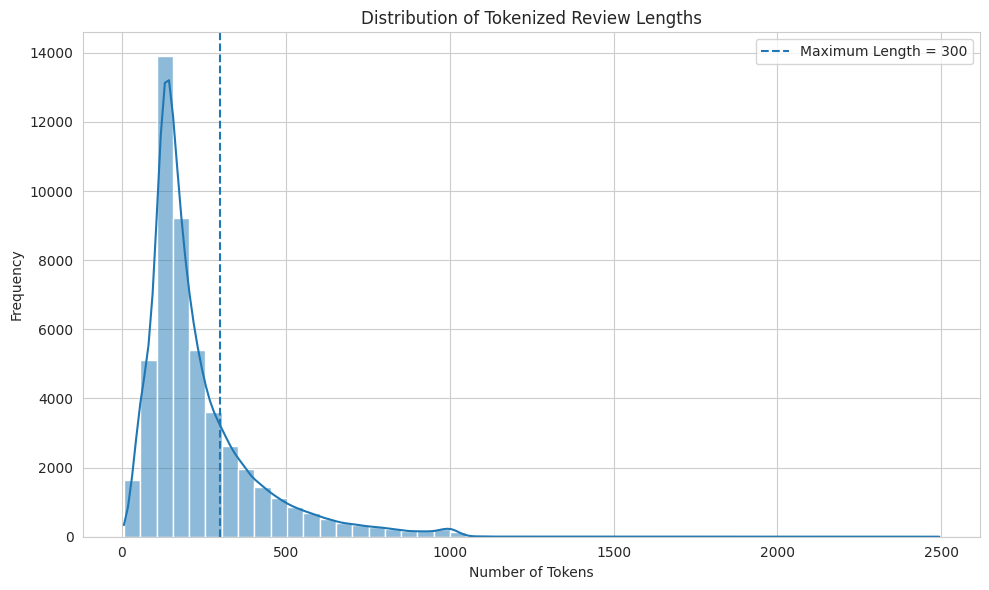

In [ ]:
sequence_lengths = [len(seq) for seq in sequences]

plt.figure(figsize=(10, 6))

sns.histplot(
    sequence_lengths,
    bins=50,
    kde=True
)

plt.axvline(
    MAX_LEN,
    linestyle='--',
    label='Maximum Length = 300'
)

plt.title('Distribution of Tokenized Review Lengths')
plt.xlabel('Number of Tokens')
plt.ylabel('Frequency')
plt.legend()

plt.tight_layout()

plt.savefig(
    '06_sequence_length_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['cleaned_review'],
    df['sentiment_encoded'],
    test_size=0.20,
    random_state=42,
    stratify=df['sentiment_encoded']
)

print("Dataset splitting completed!")

print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))

Dataset splitting completed!
Training samples: 40000
Testing samples: 10000


In [ ]:
MAX_WORDS = 20000
MAX_LEN = 300

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train_text)

print("Tokenizer fitted on training data!")
print("Vocabulary size:", len(tokenizer.word_index))

Tokenizer fitted on training data!
Vocabulary size: 90384


In [ ]:
X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

print("Training and testing sequences created!")

Training and testing sequences created!


In [ ]:
X_train = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

y_train = np.array(y_train)
y_test = np.array(y_test)

print("Final data preparation completed!")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Final data preparation completed!
X_train: (40000, 300)
X_test: (10000, 300)
y_train: (40000,)
y_test: (10000,)


In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)
print("ANN libraries imported successfully!")

TensorFlow version: 2.21.0
ANN libraries imported successfully!


In [ ]:
ann_model = Sequential([

    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        input_length=MAX_LEN
    ),

    GlobalAveragePooling1D(),

    Dense(64, activation='relu'),

    Dropout(0.5),

    Dense(1, activation='sigmoid')

])

ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("ANN Model created successfully!")

ANN Model created successfully!


In [ ]:
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

ann_history = ann_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

print("ANN Model training completed!")

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.7124 - loss: 0.5650 - val_accuracy: 0.7700 - val_loss: 0.4545
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step - accuracy: 0.8659 - loss: 0.3303 - val_accuracy: 0.8717 - val_loss: 0.3024
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.9005 - loss: 0.2594 - val_accuracy: 0.8692 - val_loss: 0.2932
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - accuracy: 0.9141 - loss: 0.2242 - val_accuracy: 0.8802 - val_loss: 0.2803
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.9155 - loss: 0.2184 - val_accuracy: 0.8585 - val_loss: 0.3401
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 12s 44ms/step - accuracy: 0.9282 - loss: 0.1923 - val_accuracy: 0.8687 - val_loss: 0.3122
ANN Model training completed!


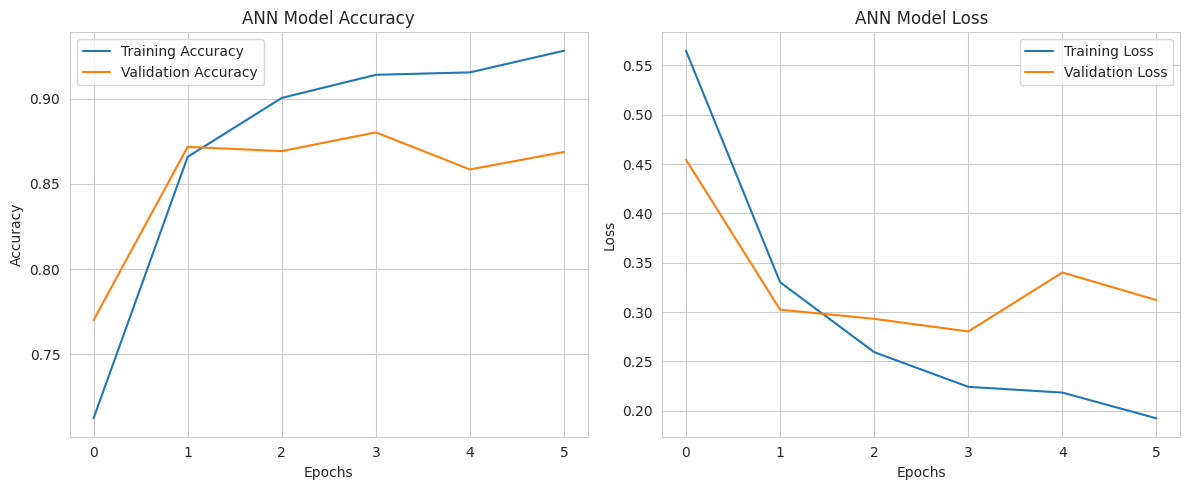

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy Graph
plt.subplot(1, 2, 1)

plt.plot(
    ann_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    ann_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('ANN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss Graph
plt.subplot(1, 2, 2)

plt.plot(
    ann_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    ann_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('ANN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()

plt.savefig(
    '07_ANN_training_performance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
test_loss, test_accuracy = ann_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nANN Model Test Results")
print("----------------------")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8898 - loss: 0.2717

ANN Model Test Results
----------------------
Test Loss: 0.2717
Test Accuracy: 88.98 %


In [ ]:
y_pred_probability = ann_model.predict(X_test)

y_pred = (y_pred_probability >= 0.5).astype(int).flatten()

print("Predictions generated successfully!")

print("\nActual Labels:", y_test[:10])
print("Predicted Labels:", y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predictions generated successfully!

Actual Labels: [0 0 1 0 0 0 0 0 0 0]
Predicted Labels: [0 0 1 0 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import classification_report

print("ANN Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Negative', 'Positive']
    )
)

ANN Classification Report:

              precision    recall  f1-score   support

    Negative       0.87      0.91      0.89      5000
    Positive       0.91      0.86      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



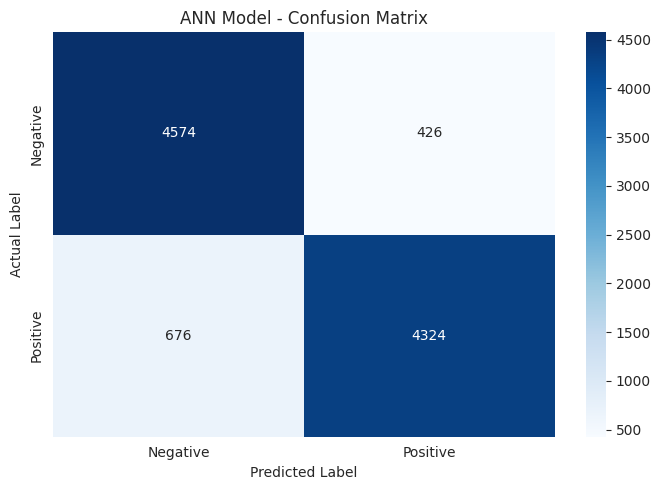

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('ANN Model - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.tight_layout()

plt.savefig(
    '08_ANN_confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
ann_model.save('IMDb_ANN_Model.keras')

print("ANN model saved successfully!")

ANN model saved successfully!


In [ ]:
from tensorflow.keras.layers import SimpleRNN

print("SimpleRNN imported successfully!")

SimpleRNN imported successfully!


In [ ]:
rnn_model = Sequential([

    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64
    ),

    SimpleRNN(
        64,
        activation='tanh'
    ),

    Dropout(0.5),

    Dense(1, activation='sigmoid')

])

rnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("RNN Model created successfully!")

RNN Model created successfully!


In [ ]:
rnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
rnn_history = rnn_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)

print("RNN Model training completed!")

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 52s 175ms/step - accuracy: 0.4982 - loss: 0.6962 - val_accuracy: 0.5048 - val_loss: 0.6938
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 79s 165ms/step - accuracy: 0.5128 - loss: 0.7232 - val_accuracy: 0.5060 - val_loss: 0.6936
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 75s 141ms/step - accuracy: 0.5000 - loss: 0.6993 - val_accuracy: 0.5030 - val_loss: 0.6933
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 44s 154ms/step - accuracy: 0.5000 - loss: 0.6948 - val_accuracy: 0.4978 - val_loss: 0.6941
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 39s 138ms/step - accuracy: 0.5020 - loss: 0.6939 - val_accuracy: 0.5005 - val_loss: 0.6930
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 40s 143ms/step - accuracy: 0.4995 - loss: 0.6939 - val_accuracy: 0.5000 - val_loss: 0.6945
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 39s 136ms/step - accuracy: 0.5076 - loss: 0.6937 - val_accuracy: 0.4942 - val_loss: 0.6933
RNN Model training completed!


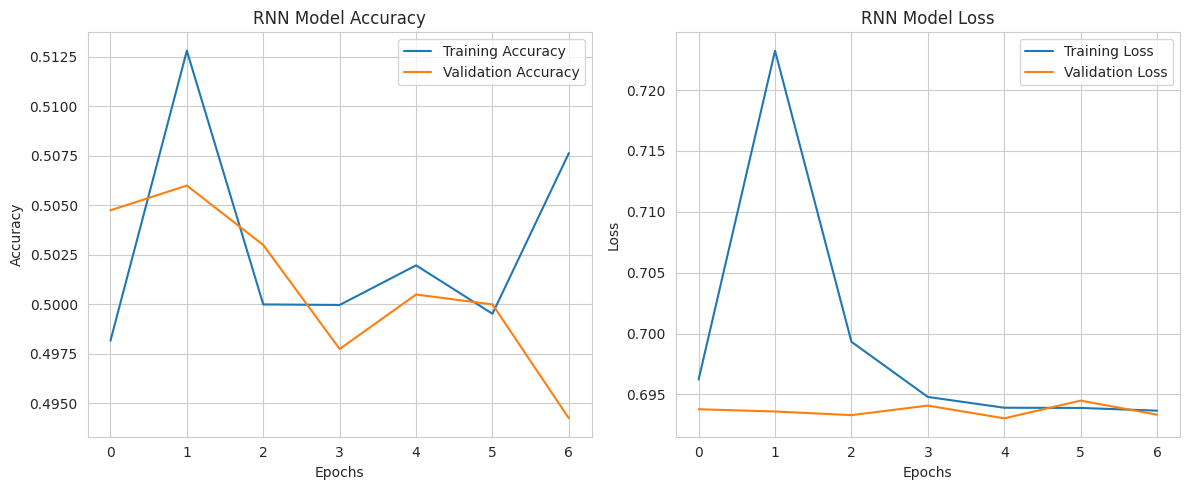

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    rnn_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    rnn_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('RNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    rnn_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    rnn_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('RNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()

plt.savefig(
    '09_RNN_training_performance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
rnn_test_loss, rnn_test_accuracy = rnn_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nRNN Model Test Results")
print("----------------------")

print("Test Loss:", round(rnn_test_loss, 4))
print("Test Accuracy:", round(rnn_test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.5062 - loss: 0.6931

RNN Model Test Results
----------------------
Test Loss: 0.6931
Test Accuracy: 50.62 %


In [ ]:
rnn_y_pred_probability = rnn_model.predict(X_test)

rnn_y_pred = (
    rnn_y_pred_probability >= 0.5
).astype(int).flatten()

print("RNN predictions generated successfully!")

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step
RNN predictions generated successfully!


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        rnn_y_pred,
        target_names=['Negative', 'Positive']
    )
)

              precision    recall  f1-score   support

    Negative       0.51      0.23      0.31      5000
    Positive       0.50      0.79      0.61      5000

    accuracy                           0.51     10000
   macro avg       0.51      0.51      0.46     10000
weighted avg       0.51      0.51      0.46     10000



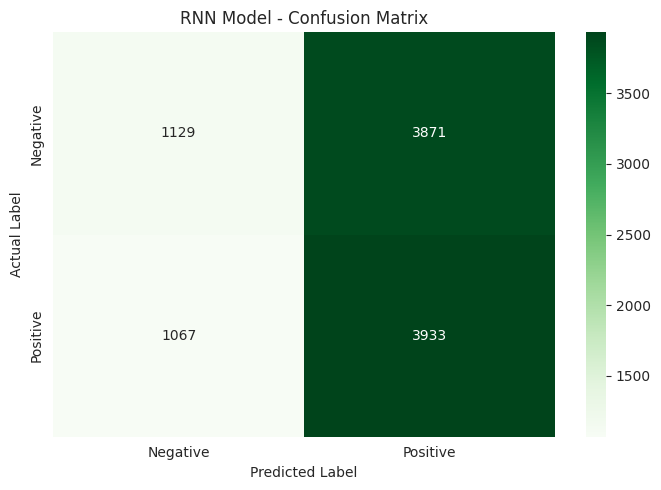

In [ ]:
rnn_cm = confusion_matrix(y_test, rnn_y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    rnn_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('RNN Model - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.tight_layout()

plt.savefig(
    '10_RNN_confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
rnn_model.save('IMDb_RNN_Model.keras')

print("RNN model saved successfully!")

RNN model saved successfully!


In [ ]:
from tensorflow.keras.layers import LSTM

In [ ]:
lstm_model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=64),
    LSTM(64),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
lstm_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
lstm_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[lstm_early_stopping],
    verbose=1
)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 169s 576ms/step - accuracy: 0.5149 - loss: 0.6926 - val_accuracy: 0.5200 - val_loss: 0.6912
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 158s 557ms/step - accuracy: 0.5406 - loss: 0.6857 - val_accuracy: 0.5508 - val_loss: 0.6680
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 156s 555ms/step - accuracy: 0.5572 - loss: 0.6590 - val_accuracy: 0.5397 - val_loss: 0.6803
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 127s 450ms/step - accuracy: 0.5679 - loss: 0.6509 - val_accuracy: 0.5318 - val_loss: 0.6889


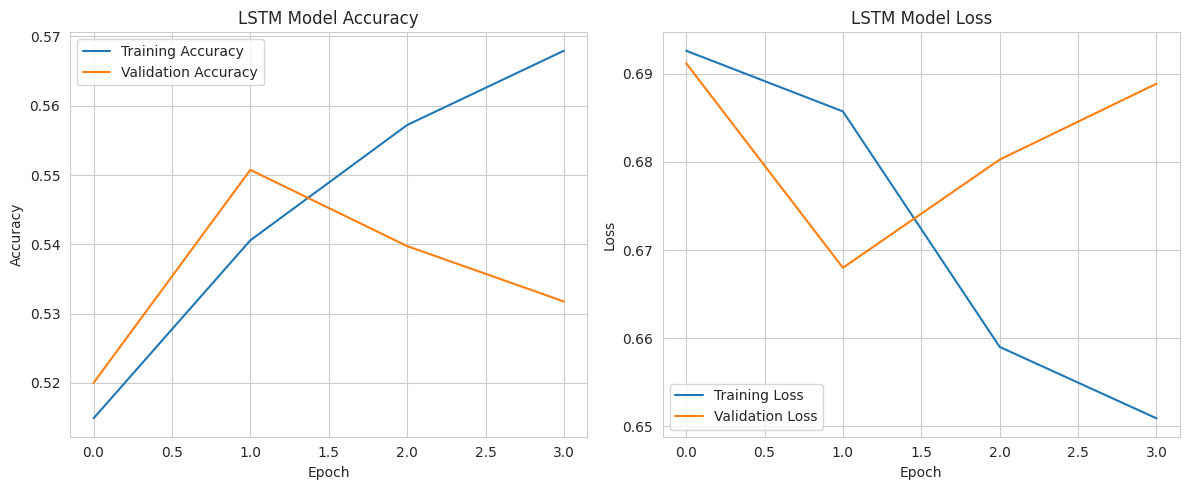

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(lstm_history.history['accuracy'], label='Training Accuracy')
plt.plot(lstm_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('LSTM Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(lstm_history.history['loss'], label='Training Loss')
plt.plot(lstm_history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig('11_LSTM_training_performance.png', dpi=300)
plt.show()

In [ ]:
lstm_test_loss, lstm_test_accuracy = lstm_model.evaluate(X_test, y_test)

print("LSTM Test Loss:", lstm_test_loss)
print("LSTM Test Accuracy:", lstm_test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.5548 - loss: 0.6648
LSTM Test Loss: 0.6648184657096863
LSTM Test Accuracy: 0.5547999739646912


In [ ]:
lstm_y_pred_probability = lstm_model.predict(X_test)

lstm_y_pred = (lstm_y_pred_probability > 0.5).astype(int).flatten()

313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step


In [ ]:
from sklearn.metrics import classification_report

print("LSTM Classification Report:")
print(classification_report(
    y_test,
    lstm_y_pred,
    target_names=['Negative', 'Positive']
))

LSTM Classification Report:
              precision    recall  f1-score   support

    Negative       0.53      0.98      0.69      5000
    Positive       0.87      0.13      0.23      5000

    accuracy                           0.55     10000
   macro avg       0.70      0.55      0.46     10000
weighted avg       0.70      0.55      0.46     10000



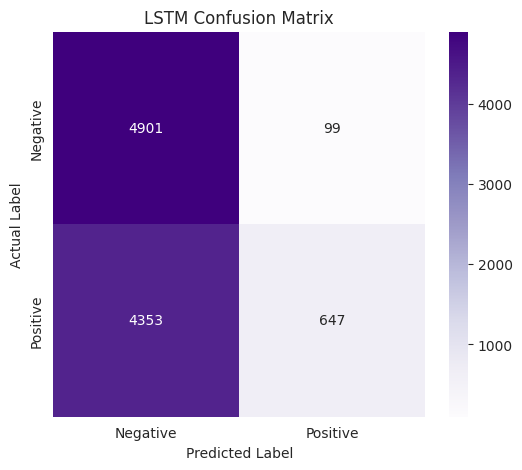

In [ ]:
lstm_cm = confusion_matrix(y_test, lstm_y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    lstm_cm,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('LSTM Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.savefig('12_LSTM_confusion_matrix.png', dpi=300)
plt.show()

In [ ]:
lstm_model.save('IMDb_LSTM_Model.keras')

print("LSTM Model Saved Successfully!")

LSTM Model Saved Successfully!


In [ ]:
from tensorflow.keras.layers import Bidirectional

In [ ]:
bilstm_model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=64),
    Bidirectional(LSTM(64)),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

bilstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
bilstm_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
bilstm_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

bilstm_history = bilstm_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[bilstm_early_stopping],
    verbose=1
)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 232s 806ms/step - accuracy: 0.7349 - loss: 0.5188 - val_accuracy: 0.8338 - val_loss: 0.3865
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 234s 829ms/step - accuracy: 0.8800 - loss: 0.3111 - val_accuracy: 0.8670 - val_loss: 0.3673
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 230s 815ms/step - accuracy: 0.9220 - loss: 0.2196 - val_accuracy: 0.8810 - val_loss: 0.3145
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 266s 827ms/step - accuracy: 0.9402 - loss: 0.1713 - val_accuracy: 0.8662 - val_loss: 0.3699
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 229s 811ms/step - accuracy: 0.9530 - loss: 0.1377 - val_accuracy: 0.8695 - val_loss: 0.3221


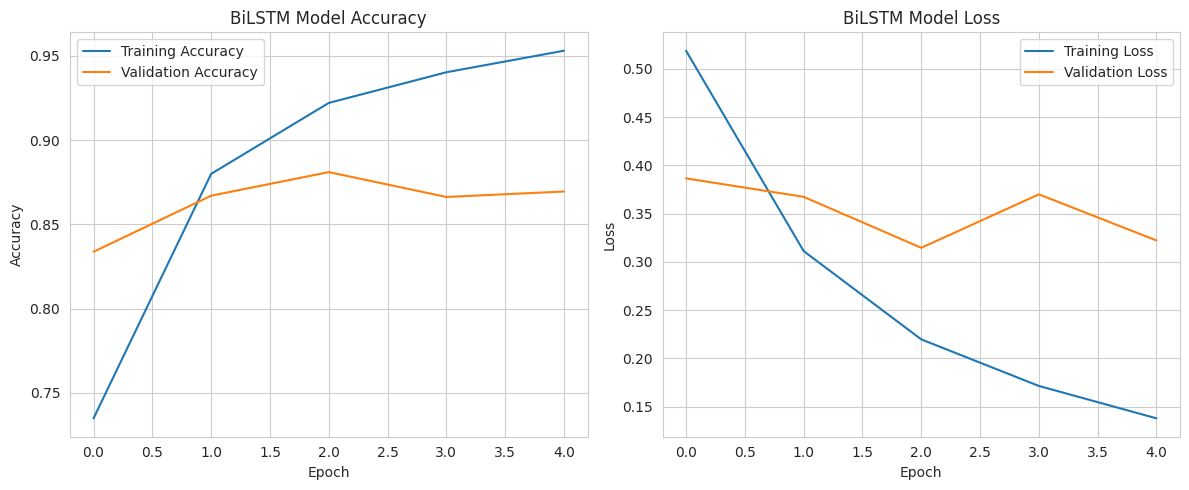

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(bilstm_history.history['accuracy'], label='Training Accuracy')
plt.plot(bilstm_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('BiLSTM Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(bilstm_history.history['loss'], label='Training Loss')
plt.plot(bilstm_history.history['val_loss'], label='Validation Loss')
plt.title('BiLSTM Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig('13_BiLSTM_training_performance.png', dpi=300)
plt.show()

In [ ]:
bilstm_test_loss, bilstm_test_accuracy = bilstm_model.evaluate(
    X_test, y_test
)

print("BiLSTM Test Loss:", bilstm_test_loss)
print("BiLSTM Test Accuracy:", bilstm_test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 20s 64ms/step - accuracy: 0.8805 - loss: 0.3311
BiLSTM Test Loss: 0.3310544192790985
BiLSTM Test Accuracy: 0.8805000185966492


In [ ]:
bilstm_y_pred_probability = bilstm_model.predict(X_test)

bilstm_y_pred = (
    bilstm_y_pred_probability > 0.5
).astype(int).flatten()

313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 68ms/step


In [ ]:
print("BiLSTM Classification Report:")

print(classification_report(
    y_test,
    bilstm_y_pred,
    target_names=['Negative', 'Positive']
))

BiLSTM Classification Report:
              precision    recall  f1-score   support

    Negative       0.85      0.93      0.89      5000
    Positive       0.92      0.83      0.87      5000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



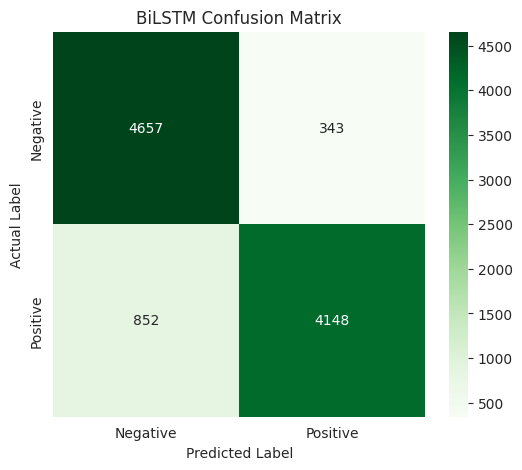

In [ ]:
bilstm_cm = confusion_matrix(y_test, bilstm_y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    bilstm_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('BiLSTM Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.savefig('14_BiLSTM_confusion_matrix.png', dpi=300)
plt.show()

In [ ]:
bilstm_model.save('IMDb_BiLSTM_Model.keras')

print("BiLSTM Model Saved Successfully!")

BiLSTM Model Saved Successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
models = {
    'ANN': y_pred,
    'SimpleRNN': rnn_y_pred,
    'LSTM': lstm_y_pred,
    'BiLSTM': bilstm_y_pred
}

comparison_results = []

for model_name, predictions in models.items():
    comparison_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1-Score': f1_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison_results)

In [ ]:
print("Model Performance Comparison:")
display(comparison_df.round(4))

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,ANN,0.8898,0.9103,0.8648,0.8870
1,SimpleRNN,0.5062,0.5040,0.7866,0.6143
2,LSTM,0.5548,0.8673,0.1294,0.2252
3,BiLSTM,0.8805,0.9236,0.8296,0.8741


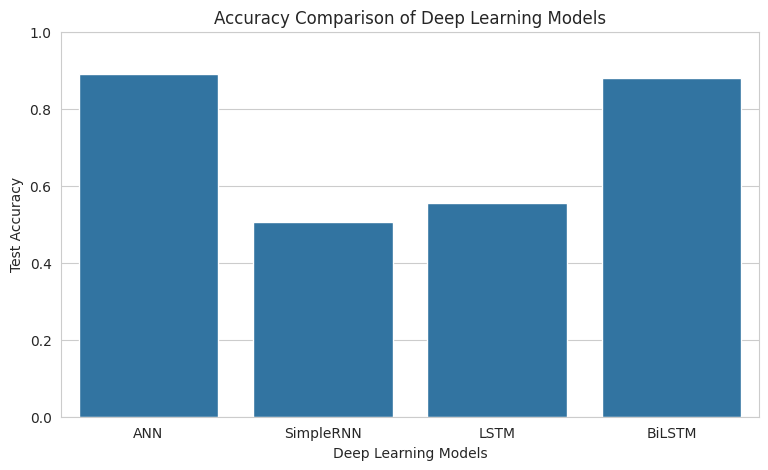

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_df,
    x='Model',
    y='Accuracy'
)

plt.title('Accuracy Comparison of Deep Learning Models')
plt.xlabel('Deep Learning Models')
plt.ylabel('Test Accuracy')
plt.ylim(0, 1)

plt.savefig('15_Model_Accuracy_Comparison.png', dpi=300)
plt.show()

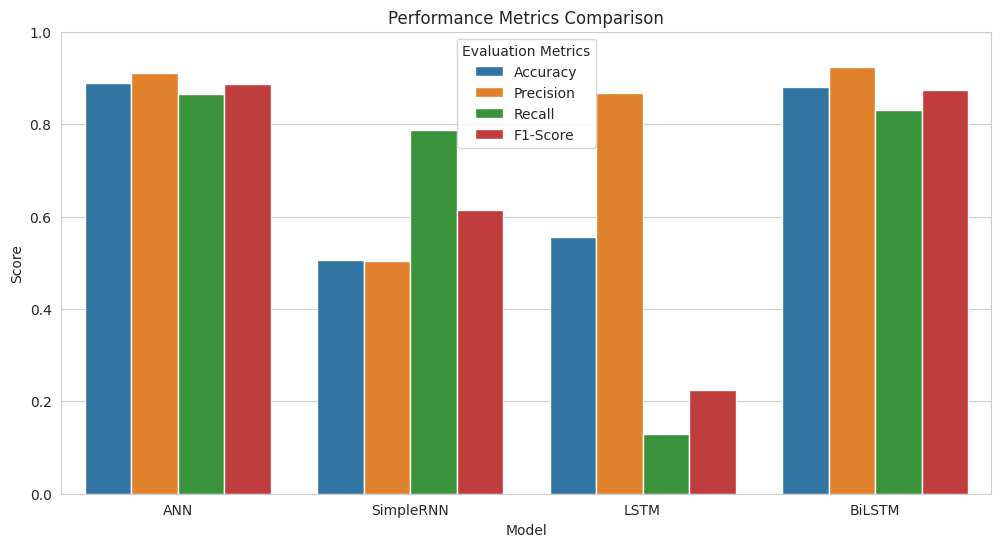

In [ ]:
comparison_melted = comparison_df.melt(
    id_vars='Model',
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_melted,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title('Performance Metrics Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.legend(title='Evaluation Metrics')

plt.savefig('16_All_Metrics_Comparison.png', dpi=300)
plt.show()

In [ ]:
comparison_df.to_csv(
    'IMDb_Model_Comparison_Results.csv',
    index=False
)

print("Comparison Results Saved Successfully!")

Comparison Results Saved Successfully!


In [ ]:
prediction_results = {
    'ANN': y_pred,
    'SimpleRNN': rnn_y_pred,
    'LSTM': lstm_y_pred,
    'BiLSTM': bilstm_y_pred
}

for model_name, predictions in prediction_results.items():
    print(f"\n{model_name}")
    print("Negative Predictions:", (predictions == 0).sum())
    print("Positive Predictions:", (predictions == 1).sum())


ANN
Negative Predictions: 5250
Positive Predictions: 4750

SimpleRNN
Negative Predictions: 2196
Positive Predictions: 7804

LSTM
Negative Predictions: 9254
Positive Predictions: 746

BiLSTM
Negative Predictions: 5509
Positive Predictions: 4491


In [ ]:
from sklearn.metrics import confusion_matrix

all_models = {
    'ANN': y_pred,
    'SimpleRNN': rnn_y_pred,
    'LSTM': lstm_y_pred,
    'BiLSTM': bilstm_y_pred
}

for model_name, predictions in all_models.items():
    cm = confusion_matrix(y_test, predictions)

    print(f"\n{'='*35}")
    print(f"{model_name} Confusion Matrix")
    print(cm)

    tn, fp, fn, tp = cm.ravel()

    print("True Negative:", tn)
    print("False Positive:", fp)
    print("False Negative:", fn)
    print("True Positive:", tp)


ANN Confusion Matrix
[[4574  426]
 [ 676 4324]]
True Negative: 4574
False Positive: 426
False Negative: 676
True Positive: 4324

SimpleRNN Confusion Matrix
[[1129 3871]
 [1067 3933]]
True Negative: 1129
False Positive: 3871
False Negative: 1067
True Positive: 3933

LSTM Confusion Matrix
[[4901   99]
 [4353  647]]
True Negative: 4901
False Positive: 99
False Negative: 4353
True Positive: 647

BiLSTM Confusion Matrix
[[4657  343]
 [ 852 4148]]
True Negative: 4657
False Positive: 343
False Negative: 852
True Positive: 4148


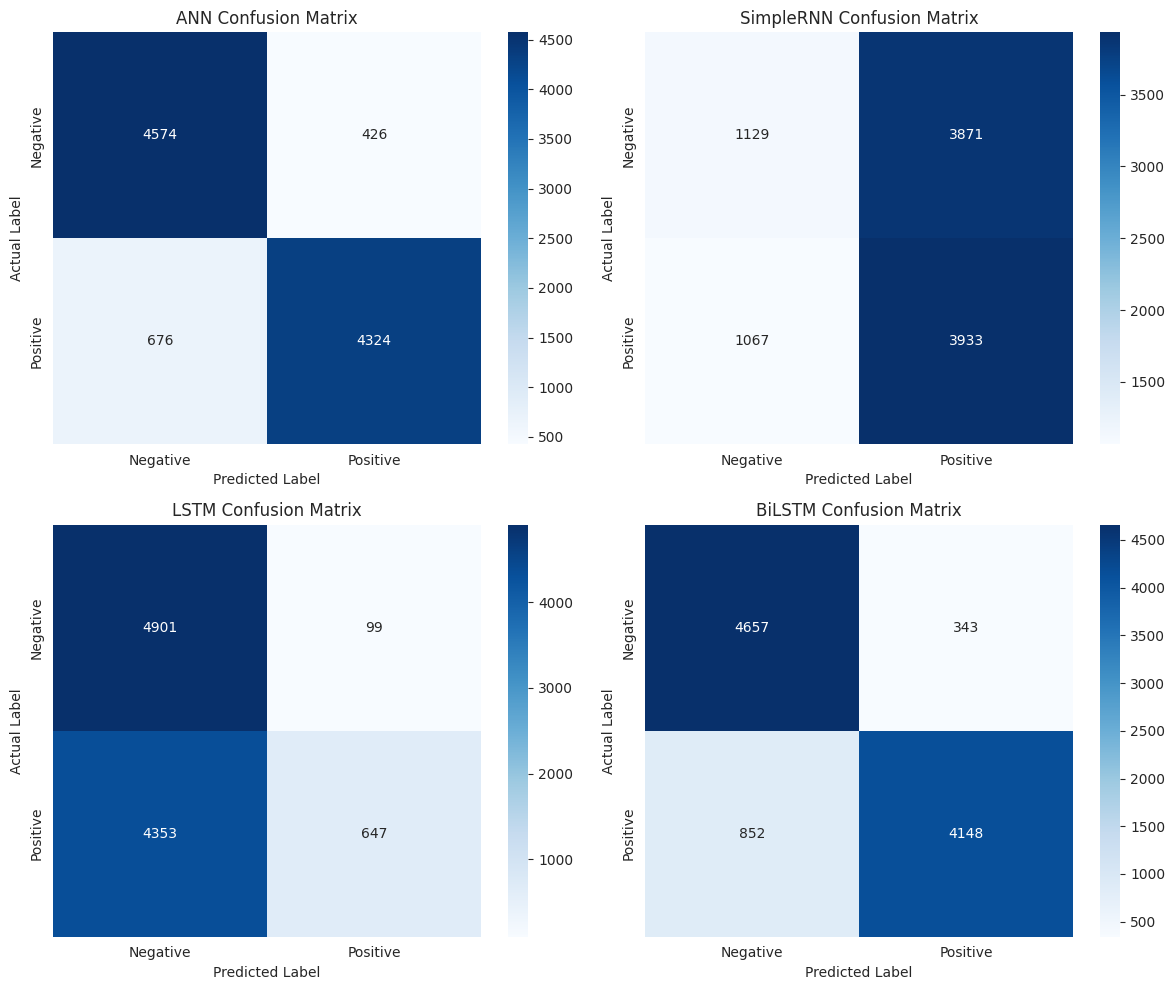

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (model_name, predictions) in zip(
    axes.flatten(), all_models.items()
):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Negative', 'Positive'],
        yticklabels=['Negative', 'Positive'],
        ax=ax
    )

    ax.set_title(f'{model_name} Confusion Matrix')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.tight_layout()
plt.savefig('17_All_Models_Confusion_Matrices.png', dpi=300)
plt.show()

In [ ]:
# Check duplicate reviews
duplicate_reviews = df[df.duplicated(subset=['review'], keep=False)]

print("Total duplicate review rows:", len(duplicate_reviews))

# Check reviews with conflicting sentiment labels
conflicting_reviews = (
    df.groupby('review')['sentiment_encoded']
    .nunique()
)

conflicting_reviews = conflicting_reviews[conflicting_reviews > 1]

print("Reviews with conflicting labels:", len(conflicting_reviews))

Total duplicate review rows: 824
Reviews with conflicting labels: 0


In [ ]:
df_clean = df.drop_duplicates(
    subset=['review'],
    keep='first'
).copy()

df_clean = df_clean.reset_index(drop=True)

print("Original Dataset Size:", len(df))
print("Dataset Size After Removing Duplicates:", len(df_clean))
print("Remaining Duplicate Reviews:", df_clean.duplicated(subset=['review']).sum())

Original Dataset Size: 50000
Dataset Size After Removing Duplicates: 49582
Remaining Duplicate Reviews: 0


Sentiment Distribution After Deduplication:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


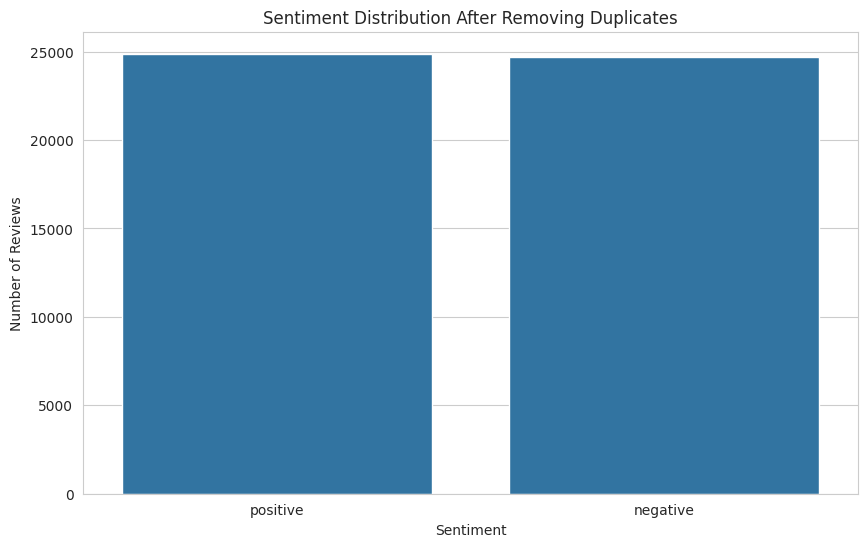

In [ ]:
print("Sentiment Distribution After Deduplication:")
print(df_clean['sentiment'].value_counts())

sns.countplot(data=df_clean, x='sentiment')
plt.title('Sentiment Distribution After Removing Duplicates')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

In [ ]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df_clean['cleaned_review'],
    df_clean['sentiment_encoded'],
    test_size=0.20,
    random_state=42,
    stratify=df_clean['sentiment_encoded']
)

print("Training Samples:", len(X_train_text))
print("Testing Samples:", len(X_test_text))

Training Samples: 39665
Testing Samples: 9917


In [ ]:
MAX_WORDS = 20000
MAX_LEN = 300

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

X_train = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

y_train = np.array(y_train)
y_test = np.array(y_test)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (39665, 300)
X_test Shape: (9917, 300)
y_train Shape: (39665,)
y_test Shape: (9917,)


In [ ]:
final_comparison = comparison_df.copy()

final_comparison[['Accuracy', 'Precision', 'Recall', 'F1-Score']] = (
    final_comparison[['Accuracy', 'Precision', 'Recall', 'F1-Score']] * 100
)

final_comparison = final_comparison.round(2)

display(final_comparison)

,Model,Accuracy,Precision,Recall,F1-Score
0,ANN,88.98,91.03,86.48,88.70
1,SimpleRNN,50.62,50.40,78.66,61.43
2,LSTM,55.48,86.73,12.94,22.52
3,BiLSTM,88.05,92.36,82.96,87.41


In [ ]:
accuracy_ranking = final_comparison.sort_values(
    by='Accuracy',
    ascending=False
)

print("Model Accuracy Ranking:")
display(accuracy_ranking[['Model', 'Accuracy']])

Model Accuracy Ranking:


,Model,Accuracy
0,ANN,88.98
3,BiLSTM,88.05
2,LSTM,55.48
1,SimpleRNN,50.62


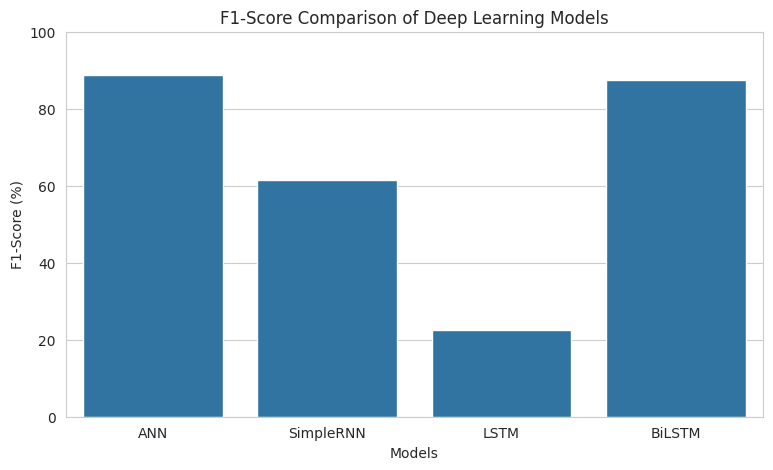

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=final_comparison,
    x='Model',
    y='F1-Score'
)

plt.title('F1-Score Comparison of Deep Learning Models')
plt.xlabel('Models')
plt.ylabel('F1-Score (%)')
plt.ylim(0, 100)

plt.savefig('18_F1_Score_Comparison.png', dpi=300)
plt.show()

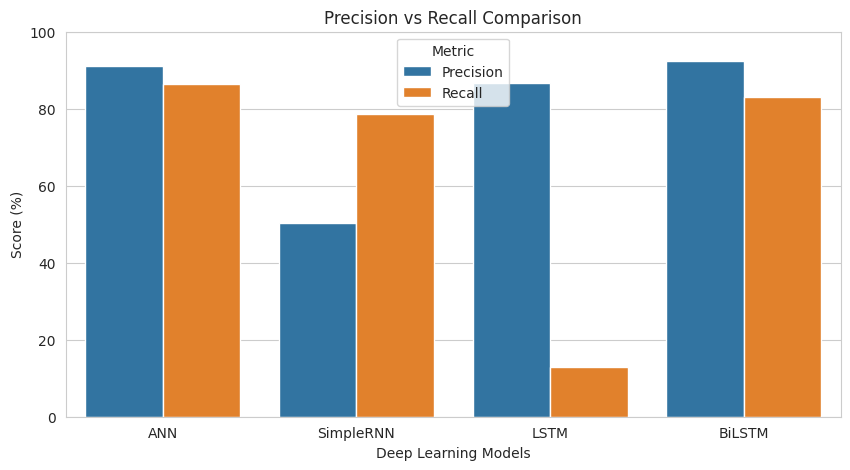

In [ ]:
precision_recall = final_comparison.melt(
    id_vars='Model',
    value_vars=['Precision', 'Recall'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=precision_recall,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title('Precision vs Recall Comparison')
plt.xlabel('Deep Learning Models')
plt.ylabel('Score (%)')
plt.ylim(0, 100)

plt.savefig('19_Precision_Recall_Comparison.png', dpi=300)
plt.show()

In [ ]:
final_comparison.to_csv(
    'IMDb_Final_Research_Results.csv',
    index=False
)

print("Final Research Results Saved Successfully!")

Final Research Results Saved Successfully!


In [ ]:
print("Original Dataset Size:", len(df))
print("Total Features:", df.shape[1])
print("Duplicate Rows:", df.duplicated().sum())
print("\nDataset Columns:")
print(df.columns.tolist())
print("\nSentiment Distribution:")
print(df['sentiment'].value_counts())

Original Dataset Size: 50000
Total Features: 5
Duplicate Rows: 418

Dataset Columns:
['review', 'sentiment', 'review_length', 'cleaned_review', 'sentiment_encoded']

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [ ]:
training_histories = {
    'ANN': ann_history,
    'SimpleRNN': rnn_history,
    'LSTM': lstm_history,
    'BiLSTM': bilstm_history
}

for model_name, history in training_histories.items():
    print(
        model_name,
        "Completed Epochs:",
        len(history.history['loss'])
    )

ANN Completed Epochs: 6
SimpleRNN Completed Epochs: 7
LSTM Completed Epochs: 4
BiLSTM Completed Epochs: 5


In [ ]:
model_objects = {
    'ANN': ann_model,
    'SimpleRNN': rnn_model,
    'LSTM': lstm_model,
    'BiLSTM': bilstm_model
}

for model_name, model in model_objects.items():
    print(
        model_name,
        "Total Parameters:",
        model.count_params()
    )

ANN Total Parameters: 1284225
SimpleRNN Total Parameters: 1288321
LSTM Total Parameters: 1313089
BiLSTM Total Parameters: 1346177


In [ ]:
import os
import zipfile

figure_files = [
    '01_sentiment_distribution.png',
    '02_review_length_distribution.png',
    '03_review_length_by_sentiment.png',
    '04_positive_wordcloud.png',
    '05_negative_wordcloud.png',
    '06_sequence_length_distribution.png',
    '07_ANN_training_performance.png',
    '08_ANN_confusion_matrix.png',
    '09_RNN_training_performance.png',
    '10_RNN_confusion_matrix.png',
    '11_LSTM_training_performance.png',
    '12_LSTM_confusion_matrix.png',
    '13_BiLSTM_training_performance.png',
    '14_BiLSTM_confusion_matrix.png',
    '15_Model_Accuracy_Comparison.png',
    '16_All_Metrics_Comparison.png',
    '17_All_Models_Confusion_Matrices.png',
    '18_F1_Score_Comparison.png',
    '19_Precision_Recall_Comparison.png'
]

with zipfile.ZipFile(
    'IMDb_Research_Figures.zip',
    'w'
) as zip_file:

    for file in figure_files:
        if os.path.exists(file):
            zip_file.write(file)

print("Research Figures Export Completed!")

Research Figures Export Completed!
